In [ ]:
# Customer Analytics & Segmentation

## Project objectives

This notebook explores the cleaned retail transaction dataset to identify
business trends, understand customer purchasing behavior, and segment
customers using the RFM methodology.

### Analyses
1. Monthly revenue evolution
2. Top 10 products by revenue
3. Revenue by country
4. Monthly order evolution
5. Customer purchasing behavior
6. RFM customer segmentation

In [15]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

# Plot settings
plt.rcParams["figure.figsize"] = (12, 6)
plt.rcParams["axes.grid"] = True

In [16]:
# Load cleaned sales dataset
sales_clean = pd.read_csv(
    "../data/processed/sales_clean.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "Description": "string",
        "Country": "string"
    },
    low_memory=False
)

# Load customer dataset
customer_sales = pd.read_csv(
    "../data/processed/customer_sales.csv",
    parse_dates=["InvoiceDate"],
    dtype={
        "InvoiceNo": "string",
        "StockCode": "string",
        "Description": "string",
        "Country": "string",
        "CustomerID": "Int64"
    },
    low_memory=False
)

print("Sales dataset:", sales_clean.shape)
print("Customer dataset:", customer_sales.shape)

Sales dataset: (524878, 13)
Customer dataset: (392692, 13)


In [17]:
print("Sales dataset information:")
sales_clean.info()

print("\nMissing values:")
print(sales_clean.isna().sum())

print("\nCustomer dataset information:")
customer_sales.info()

print("\nUnique customers:")
print(customer_sales["CustomerID"].nunique())

Sales dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 524878 entries, 0 to 524877
Data columns (total 13 columns):
 #   Column           Non-Null Count   Dtype         
---  ------           --------------   -----         
 0   InvoiceNo        524878 non-null  string        
 1   StockCode        524878 non-null  string        
 2   Description      524878 non-null  string        
 3   Quantity         524878 non-null  int64         
 4   InvoiceDate      524878 non-null  datetime64[us]
 5   UnitPrice        524878 non-null  float64       
 6   CustomerID       392692 non-null  float64       
 7   Country          524878 non-null  string        
 8   IsCancellation   524878 non-null  bool          
 9   InvalidQuantity  524878 non-null  bool          
 10  InvalidPrice     524878 non-null  bool          
 11  InvalidDate      524878 non-null  bool          
 12  Revenue          524878 non-null  float64       
dtypes: bool(4), datetime64[us](1), float64(3), int64(1), strin

In [18]:
sales_clean["YearMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M")
)

monthly_revenue = (
    sales_clean.groupby("YearMonth")["Revenue"]
    .sum()
    .reset_index()
)

monthly_revenue["YearMonth"] = (
    monthly_revenue["YearMonth"].astype(str)
)

print(monthly_revenue)

   YearMonth      Revenue
0    2010-12   821,452.73
1    2011-01   689,811.61
2    2011-02   522,545.56
3    2011-03   716,215.26
4    2011-04   536,968.49
5    2011-05   769,296.61
6    2011-06   760,547.01
7    2011-07   718,076.12
8    2011-08   757,841.38
9    2011-09 1,056,435.19
10   2011-10 1,151,263.73
11   2011-11 1,503,866.78
12   2011-12   637,790.33


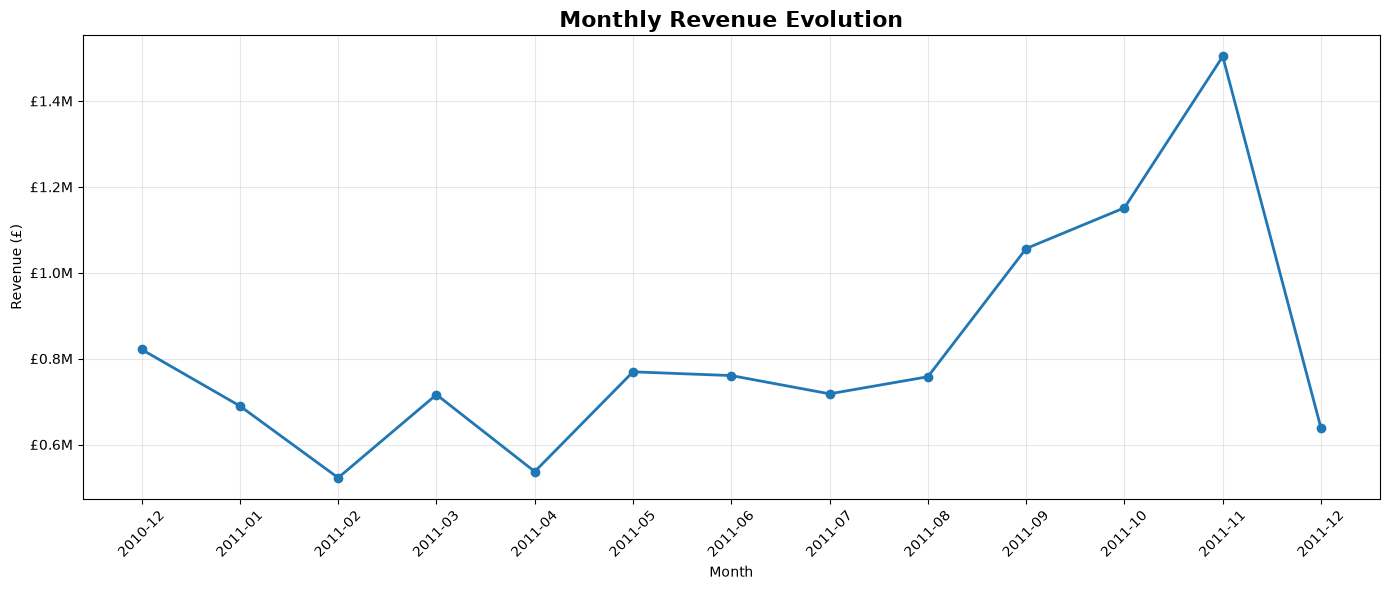

In [19]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_revenue["YearMonth"],
    monthly_revenue["Revenue"],
    marker="o",
    linewidth=2
)

plt.title(
    "Monthly Revenue Evolution",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Month")
plt.ylabel("Revenue (£)")

plt.gca().yaxis.set_major_formatter(
    plt.FuncFormatter(lambda x, _: f"£{x/1_000_000:.1f}M")
)

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
### Business insights

- Revenue fluctuates during the first months of 2011.
- Revenue increases significantly from September 2011.
- November 2011 records the highest monthly revenue.
- December 2011 is incomplete because the dataset ends on December 9.

Further investigation is required to understand the increase in revenue
during the final months of 2011.

In [20]:
top_products = (
    sales_clean
    .groupby(["StockCode", "Description"], dropna=False)["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

print(top_products)

  StockCode                         Description    Revenue
0       DOT                      DOTCOM POSTAGE 206,248.77
1     22423            REGENCY CAKESTAND 3 TIER 174,156.54
2     23843         PAPER CRAFT , LITTLE BIRDIE 168,469.60
3    85123A  WHITE HANGING HEART T-LIGHT HOLDER 104,284.24
4     47566                       PARTY BUNTING  99,445.23
5    85099B             JUMBO BAG RED RETROSPOT  94,159.81
6     23166      MEDIUM CERAMIC TOP STORAGE JAR  81,700.92
7      POST                             POSTAGE  78,101.88
8         M                              Manual  77,750.27
9     23084                  RABBIT NIGHT LIGHT  66,870.03


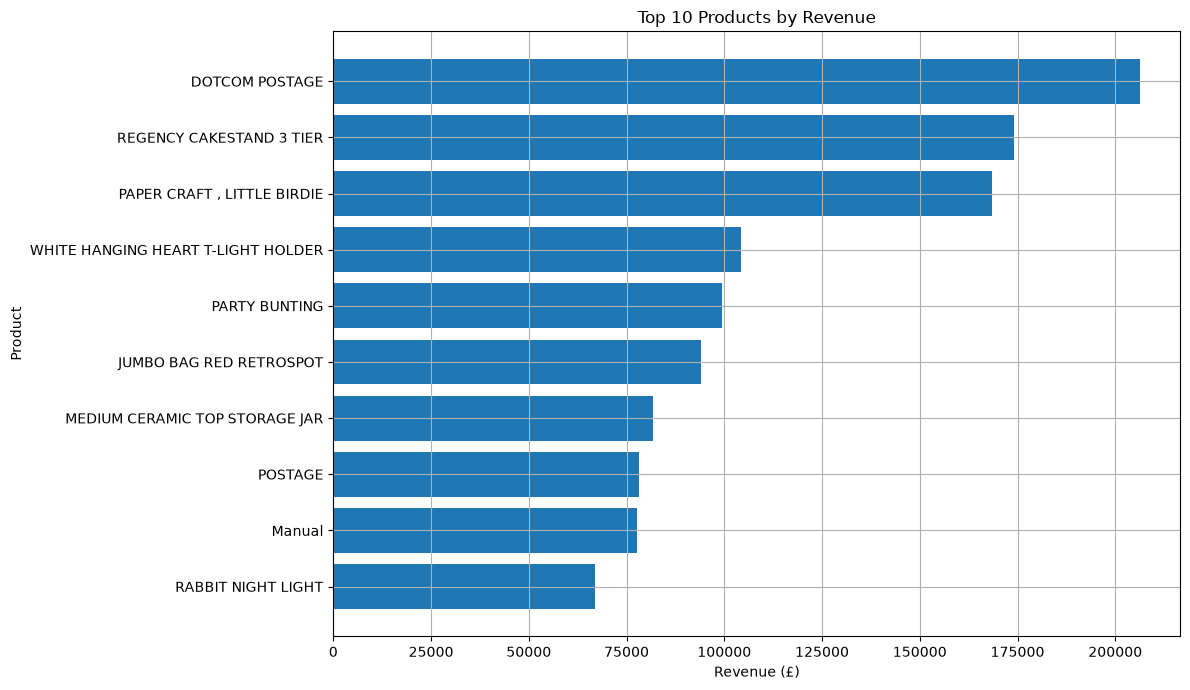

In [21]:
plt.figure(figsize=(12, 7))

plt.barh(
    top_products["Description"].fillna("Unknown"),
    top_products["Revenue"]
)

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Product")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [22]:
revenue_by_country = (
    sales_clean
    .groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(revenue_by_country.head(10))

          Country      Revenue
0  United Kingdom 9,001,744.09
1     Netherlands   285,446.34
2            EIRE   283,140.52
3         Germany   228,678.40
4          France   209,625.37
5       Australia   138,453.81
6           Spain    61,558.56
7     Switzerland    57,067.60
8         Belgium    41,196.34
9          Sweden    38,367.83


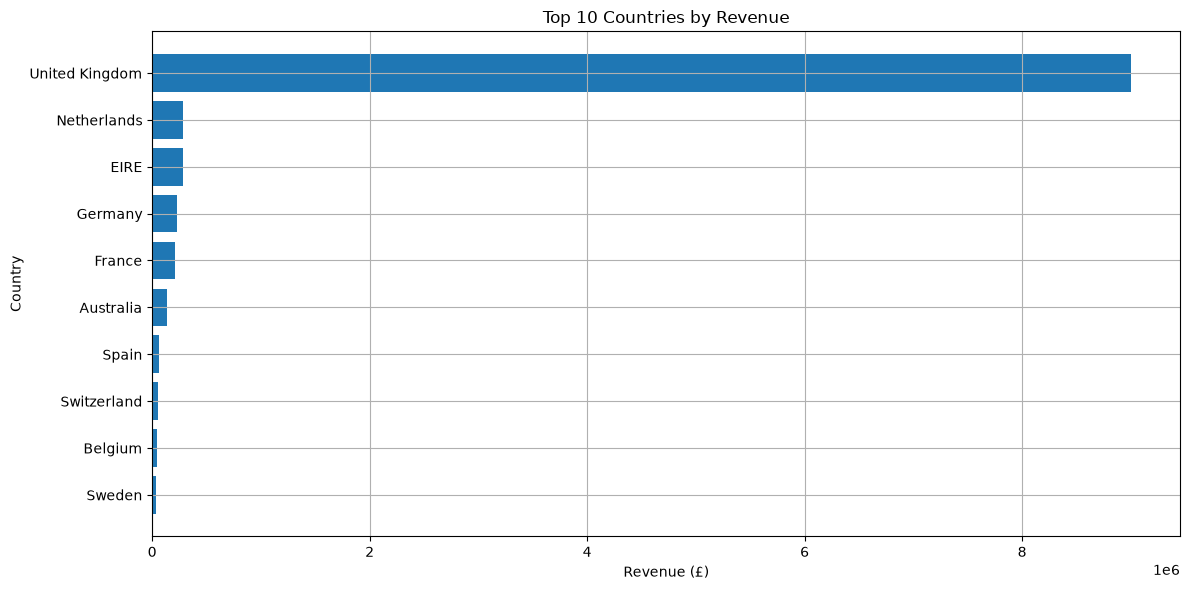

In [23]:
top_countries = revenue_by_country.head(10)

plt.figure(figsize=(12, 6))

plt.barh(
    top_countries["Country"],
    top_countries["Revenue"]
)

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

In [24]:
total_revenue = sales_clean["Revenue"].sum()

revenue_by_country["RevenueShare"] = (
    revenue_by_country["Revenue"] / total_revenue * 100
)

print(
    revenue_by_country[
        ["Country", "Revenue", "RevenueShare"]
    ].head(10)
)

          Country      Revenue  RevenueShare
0  United Kingdom 9,001,744.09         84.59
1     Netherlands   285,446.34          2.68
2            EIRE   283,140.52          2.66
3         Germany   228,678.40          2.15
4          France   209,625.37          1.97
5       Australia   138,453.81          1.30
6           Spain    61,558.56          0.58
7     Switzerland    57,067.60          0.54
8         Belgium    41,196.34          0.39
9          Sweden    38,367.83          0.36


In [25]:
sales_clean["YearMonth"] = (
    sales_clean["InvoiceDate"].dt.to_period("M")
)

monthly_orders = (
    sales_clean
    .groupby("YearMonth")["InvoiceNo"]
    .nunique()
    .reset_index()
)

monthly_orders.columns = ["YearMonth", "NumberOfOrders"]

monthly_orders["YearMonth"] = (
    monthly_orders["YearMonth"].astype(str)
)

print(monthly_orders)

   YearMonth  NumberOfOrders
0    2010-12            1559
1    2011-01            1086
2    2011-02            1100
3    2011-03            1454
4    2011-04            1246
5    2011-05            1681
6    2011-06            1533
7    2011-07            1475
8    2011-08            1361
9    2011-09            1837
10   2011-10            2040
11   2011-11            2769
12   2011-12             819


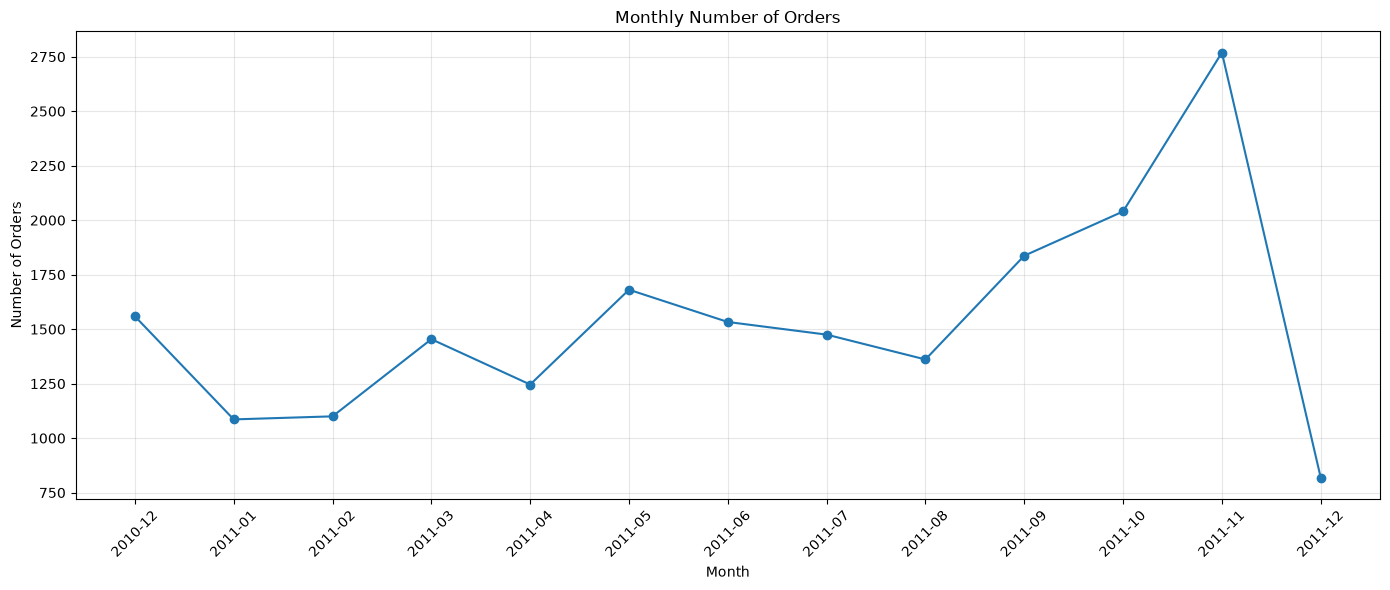

In [26]:
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_orders["YearMonth"],
    monthly_orders["NumberOfOrders"],
    marker="o"
)

plt.title("Monthly Number of Orders")
plt.xlabel("Month")
plt.ylabel("Number of Orders")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [27]:
customer_metrics = (
    customer_sales
    .groupby("CustomerID")
    .agg(
        TotalRevenue=("Revenue", "sum"),
        TotalOrders=("InvoiceNo", "nunique"),
        TotalQuantity=("Quantity", "sum"),
        AveragePurchase=("Revenue", "mean"),
        FirstPurchase=("InvoiceDate", "min"),
        LastPurchase=("InvoiceDate", "max")
    )
    .reset_index()
)

print(customer_metrics.head())

   CustomerID  TotalRevenue  TotalOrders  TotalQuantity  AveragePurchase  \
0       12346     77,183.60            1          74215        77,183.60   
1       12347      4,310.00            7           2458            23.68   
2       12348      1,797.24            4           2341            57.98   
3       12349      1,757.55            1            631            24.08   
4       12350        334.40            1            197            19.67   

        FirstPurchase        LastPurchase  
0 2011-01-18 10:01:00 2011-01-18 10:01:00  
1 2010-12-07 14:57:00 2011-12-07 15:52:00  
2 2010-12-16 19:09:00 2011-09-25 13:13:00  
3 2011-11-21 09:51:00 2011-11-21 09:51:00  
4 2011-02-02 16:01:00 2011-02-02 16:01:00  


In [28]:
top_customers = (
    customer_metrics
    .sort_values("TotalRevenue", ascending=False)
    .head(10)
)

print(top_customers)

      CustomerID  TotalRevenue  TotalOrders  TotalQuantity  AveragePurchase  \
1689       14646    280,206.02           73         196915           134.97   
4201       18102    259,657.30           60          64124           602.45   
3728       17450    194,390.79           46          69973           578.54   
3008       16446    168,472.50            2          80997        56,157.50   
1879       14911    143,711.17          201          80240            25.35   
55         12415    124,914.53           21          77374           174.95   
1333       14156    117,210.08           55          57768            84.02   
3771       17511     91,062.38           31          64549            94.56   
2702       16029     80,850.84           63          40108           335.48   
0          12346     77,183.60            1          74215        77,183.60   

           FirstPurchase        LastPurchase  
1689 2010-12-20 10:09:00 2011-12-08 12:12:00  
4201 2010-12-07 16:42:00 2011-12-09 

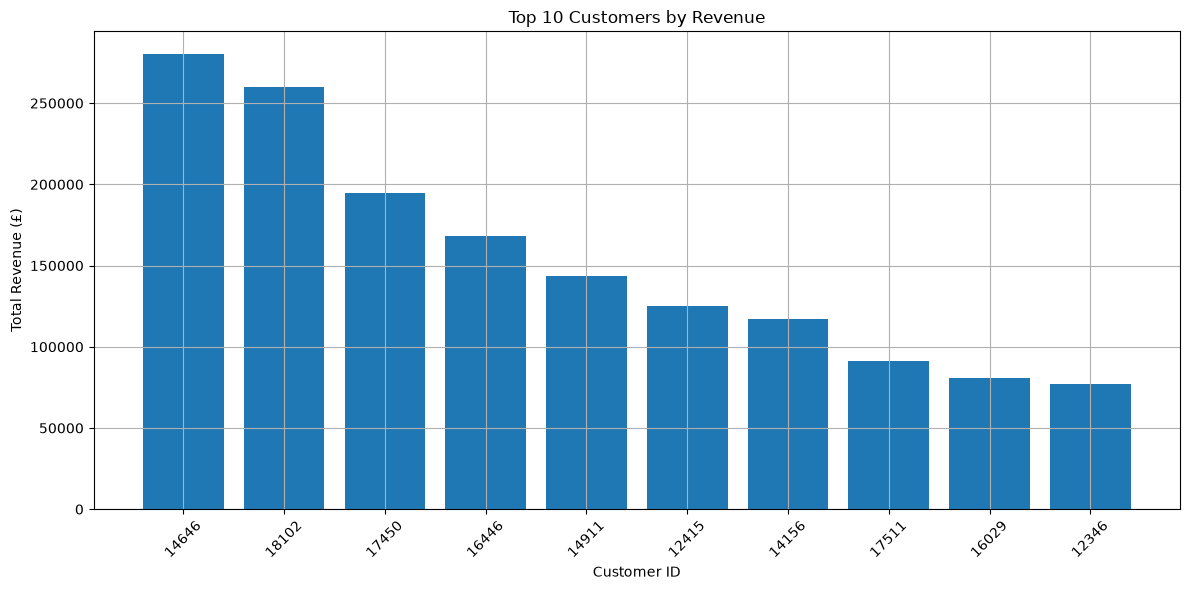

In [29]:
plt.figure(figsize=(12, 6))

plt.bar(
    top_customers["CustomerID"].astype(str),
    top_customers["TotalRevenue"]
)

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Customer ID")
plt.ylabel("Total Revenue (£)")

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [30]:
# Reference date: one day after the last transaction
reference_date = (
    customer_sales["InvoiceDate"].max()
    + pd.Timedelta(days=1)
)

rfm = (
    customer_sales
    .groupby("CustomerID")
    .agg(
        Recency=("InvoiceDate", lambda x: (
            reference_date - x.max()
        ).days),
        Frequency=("InvoiceNo", "nunique"),
        Monetary=("Revenue", "sum")
    )
    .reset_index()
)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary
0       12346      326          1 77,183.60
1       12347        2          7  4,310.00
2       12348       75          4  1,797.24
3       12349       19          1  1,757.55
4       12350      310          1    334.40


In [31]:
# Recency: lower is better
rfm["R_Score"] = pd.qcut(
    rfm["Recency"].rank(method="first"),
    4,
    labels=[4, 3, 2, 1]
).astype(int)

# Frequency: higher is better
rfm["F_Score"] = pd.qcut(
    rfm["Frequency"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

# Monetary: higher is better
rfm["M_Score"] = pd.qcut(
    rfm["Monetary"].rank(method="first"),
    4,
    labels=[1, 2, 3, 4]
).astype(int)

rfm["RFM_Score"] = (
    rfm["R_Score"]
    + rfm["F_Score"]
    + rfm["M_Score"]
)

print(rfm.head())

   CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0       12346      326          1 77,183.60        1        1        4   
1       12347        2          7  4,310.00        4        4        4   
2       12348       75          4  1,797.24        2        3        4   
3       12349       19          1  1,757.55        3        1        4   
4       12350      310          1    334.40        1        1        2   

   RFM_Score  
0          6  
1         12  
2          9  
3          8  
4          4  


In [32]:
def segment_customer(score):

    if score >= 10:
        return "Champions"

    elif score >= 8:
        return "Loyal Customers"

    elif score >= 6:
        return "Potential Customers"

    elif score >= 4:
        return "At Risk"

    else:
        return "Needs Attention"


rfm["Segment"] = rfm["RFM_Score"].apply(segment_customer)

print(rfm.head(10))

   CustomerID  Recency  Frequency  Monetary  R_Score  F_Score  M_Score  \
0       12346      326          1 77,183.60        1        1        4   
1       12347        2          7  4,310.00        4        4        4   
2       12348       75          4  1,797.24        2        3        4   
3       12349       19          1  1,757.55        3        1        4   
4       12350      310          1    334.40        1        1        2   
5       12352       36          8  2,506.04        3        4        4   
6       12353      204          1     89.00        1        1        1   
7       12354      232          1  1,079.40        1        1        3   
8       12355      214          1    459.40        1        1        2   
9       12356       23          3  2,811.43        3        3        4   

   RFM_Score              Segment  
0          6  Potential Customers  
1         12            Champions  
2          9      Loyal Customers  
3          8      Loyal Customers  
4    

In [33]:
segment_distribution = (
    rfm["Segment"]
    .value_counts()
    .reset_index()
)

segment_distribution.columns = [
    "Segment",
    "NumberOfCustomers"
]

print(segment_distribution)

               Segment  NumberOfCustomers
0            Champions               1260
1              At Risk                995
2  Potential Customers                940
3      Loyal Customers                843
4      Needs Attention                300


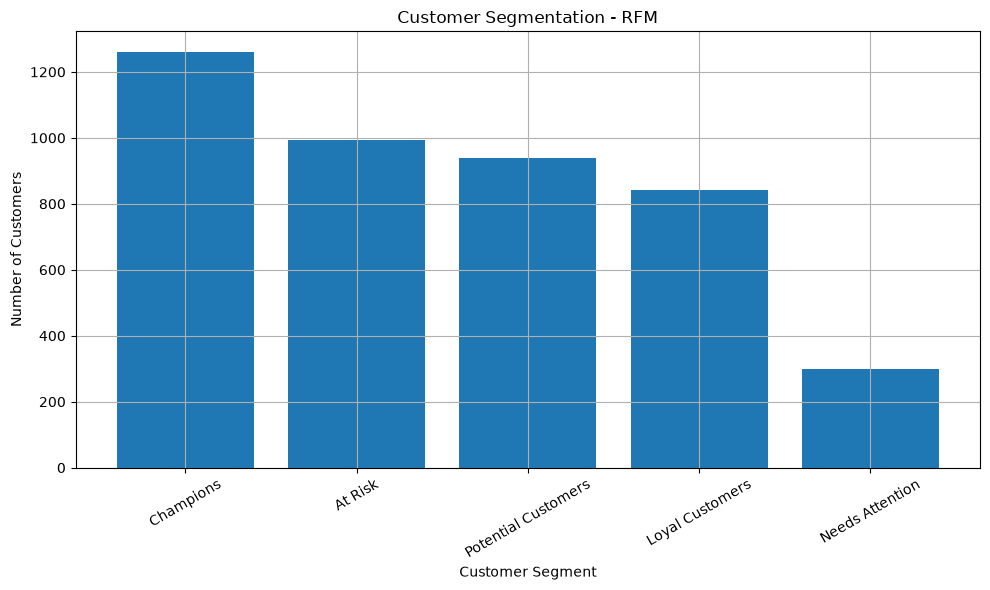

In [34]:
plt.figure(figsize=(10, 6))

plt.bar(
    segment_distribution["Segment"],
    segment_distribution["NumberOfCustomers"]
)

plt.title("Customer Segmentation - RFM")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [35]:
rfm_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

print(rfm_revenue)

               Segment     Monetary
0            Champions 6,819,332.77
1      Loyal Customers 1,054,519.62
2  Potential Customers   653,931.48
3              At Risk   311,066.79
4      Needs Attention    48,358.23


In [36]:
output_dir = Path("../data/processed")
output_dir.mkdir(parents=True, exist_ok=True)

monthly_revenue.to_csv(
    output_dir / "monthly_revenue.csv",
    index=False
)

top_products.to_csv(
    output_dir / "top_products.csv",
    index=False
)

revenue_by_country.to_csv(
    output_dir / "revenue_by_country.csv",
    index=False
)

monthly_orders.to_csv(
    output_dir / "monthly_orders.csv",
    index=False
)

customer_metrics.to_csv(
    output_dir / "customer_metrics.csv",
    index=False
)

rfm.to_csv(
    output_dir / "customer_rfm.csv",
    index=False
)

print("All analysis results exported successfully!")

All analysis results exported successfully!


# Conclusion

This exploratory data analysis provided several insights into the
retail business:

1. Monthly revenue analysis revealed changes in sales performance.
2. Product analysis identified the products generating the highest revenue.
3. Country analysis highlighted the most important markets.
4. Monthly order analysis provided insights into purchasing activity.
5. Customer analysis identified high-value customers.
6. RFM segmentation classified customers according to their purchasing behavior.

These results will be used to build a customer analytics dashboard
and support business decision-making.

In [37]:
rfm_revenue = (
    rfm.groupby("Segment")["Monetary"]
    .sum()
    .sort_values(ascending=False)
    .reset_index()
)

rfm_revenue.columns = ["Segment", "TotalRevenue"]

print(rfm_revenue)

               Segment  TotalRevenue
0            Champions  6,819,332.77
1      Loyal Customers  1,054,519.62
2  Potential Customers    653,931.48
3              At Risk    311,066.79
4      Needs Attention     48,358.23


In [38]:
segment_distribution["Percentage"] = (
    segment_distribution["NumberOfCustomers"]
    / segment_distribution["NumberOfCustomers"].sum()
    * 100
)

print(segment_distribution)

               Segment  NumberOfCustomers  Percentage
0            Champions               1260       29.05
1              At Risk                995       22.94
2  Potential Customers                940       21.67
3      Loyal Customers                843       19.43
4      Needs Attention                300        6.92


In [39]:
print("Customer sales revenue:",
      round(customer_sales["Revenue"].sum(), 2))

print("RFM monetary revenue:",
      round(rfm["Monetary"].sum(), 2))

print("Difference:",
      round(
          customer_sales["Revenue"].sum()
          - rfm["Monetary"].sum(),
          2
      ))

Customer sales revenue: 8887208.89
RFM monetary revenue: 8887208.89
Difference: 0.0
